In [1]:
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print('Libraries loaded')

Libraries loaded


### Load CSV & Prepare features by imputing missing values with medians and standardising

In [2]:
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]
panel = pd.read_csv("panel_cluster_ready.csv", parse_dates=["date"])
medians = panel[FEATURES].median()
scaler = StandardScaler().fit(panel[FEATURES].fillna(medians))
X = scaler.transform(panel[FEATURES].fillna(medians))

### Assign each whale equal weight in HDBSCAN so high-day whales (W-2, W-3) do not dominate.

In [3]:
fit_pool = panel[panel["whale_id"] != "W-7"]
rng = np.random.default_rng(42)
n_per = fit_pool.groupby("whale_id").size().min()
idx = [i for _, g in fit_pool.groupby("whale_id") for i in rng.choice(g.index, n_per, replace=False)]
X_bal = scaler.transform(panel.loc[idx, FEATURES].fillna(medians))
print(f"rows: {len(panel)} | fit: {len(idx)} ({n_per}/whale)")

rows: 457 | fit: 156 (26/whale)


### Parameter sweep on balanced fit

In [4]:
for mcs in [10, 12, 15]:
    lb = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=5).fit_predict(X_bal)
    print(f"min_cluster_size={mcs}")
    print(pd.Series(lb).value_counts().sort_index())
    print()

min_cluster_size=10
-1    89
 0    31
 1    13
 2    23
Name: count, dtype: int64

min_cluster_size=12
-1    89
 0    31
 1    13
 2    23
Name: count, dtype: int64

min_cluster_size=15
-1    88
 0    31
 1    37
Name: count, dtype: int64



we'll use `min_cluster_size=12` to land on 3 archetypes.

### Assign all whale-days to nearest cluster centroid

In [5]:
labels_bal = hdbscan.HDBSCAN(min_cluster_size=12, min_samples=5).fit_predict(X_bal)
clusters = sorted(c for c in set(labels_bal) if c >= 0)
centroids = np.array([X_bal[labels_bal == c].mean(axis=0) for c in clusters])
dists = cdist(X, centroids)
panel["cluster_v2"] = [clusters[i] for i in np.argmin(dists, axis=1)]
panel.loc[dists.min(axis=1) > np.percentile(dists.min(axis=1), 95), "cluster_v2"] = -1
print(panel["cluster_v2"].value_counts().sort_index())

cluster_v2
-1     23
 0    122
 1     77
 2    235
Name: count, dtype: int64


### Unnamed Profile Table

In [6]:
panel.groupby("cluster_v2")[FEATURES].mean().round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster_v2,,,,,,,,,,,
-1,0.042,1.130,0.923,0.220,0.335,3.130,6.739,1.217,0.591,3.039,7.485
0,0.623,4.344,0.315,0.008,0.016,1.123,5.770,6.934,0.601,2.896,12.418
1,0.936,15.740,0.029,0.000,0.000,0.091,0.286,58.416,0.936,4.573,72.084
2,0.911,13.026,0.022,0.003,0.003,1.796,6.826,17.179,0.913,2.389,35.501


these are raw numbers used to pick names in the next cell

### Archetype Names

In [7]:
CLUSTER_LABELS = {
    -1: "idle / outlier",
    0: "moderate leverage",
    1: "extreme leverage",
    2: "high-LTV hold",
}
panel["cluster_name"] = panel["cluster_v2"].map(CLUSTER_LABELS)
panel.groupby(["cluster_v2", "cluster_name"])[FEATURES].mean().round(3)

,,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster_v2,cluster_name,,,,,,,,,,,
-1,idle / outlier,0.042,1.130,0.923,0.220,0.335,3.130,6.739,1.217,0.591,3.039,7.485
0,moderate leverage,0.623,4.344,0.315,0.008,0.016,1.123,5.770,6.934,0.601,2.896,12.418
1,extreme leverage,0.936,15.740,0.029,0.000,0.000,0.091,0.286,58.416,0.936,4.573,72.084
2,high-LTV hold,0.911,13.026,0.022,0.003,0.003,1.796,6.826,17.179,0.913,2.389,35.501


- idle/outlier (-1)     → not really looping
- moderate (0)          → lower LTV, shallower loop
- high-LTV hold (2)     → high LTV, active hold / rebal
- extreme (1)           → max LTV + max loop + stale + max carry


### PCA By Archetype

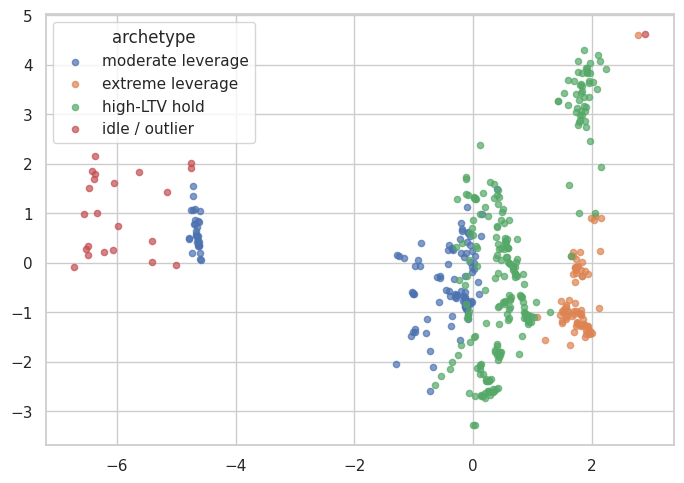

In [8]:
pca = PCA(n_components=2, random_state=42).fit_transform(X)
panel["x"], panel["y"] = pca[:, 0], pca[:, 1]
order = ["moderate leverage", "extreme leverage", "high-LTV hold", "idle / outlier"]
plt.figure(figsize=(7, 5))
for name in order:
    s = panel[panel["cluster_name"] == name]
    if len(s):
        plt.scatter(s["x"], s["y"], label=name, alpha=0.7, s=20)
plt.legend(title="archetype")
plt.tight_layout()
plt.show()

- Extreme leverage - sits centre-right, below the midline: high LTV + deep loop + stale rebalance + high carry. Almost all W-2; the single point far top-right is one W-3 day, not the main extreme group.
- High-LTV hold - the large centre-right cloud, including the upper band (high LTV, deep loop, more rebalancing than extreme).
- Moderate leverage - split on the left: W-4/W-5 core (80% LTV) plus a W-3 patch further left (40% LTV, lighter loop) in the same label.
- Idle / outlier - the small scatter far left (near-zero LTV) plus a few centroid-distance outliers.

In [9]:
membership = (
    panel.groupby(["whale_id", "cluster_name"]).size()
    .groupby(level=0, group_keys=False)
    .apply(lambda s: (s / s.sum() * 100).round(1))
    .unstack(fill_value=0)
)
membership

cluster_name,extreme leverage,high-LTV hold,idle / outlier,moderate leverage
whale_id,,,,
W-1,1.3,98.7,0.0,0.0
W-2,85.2,6.8,8.0,0.0
W-3,0.7,48.2,11.5,39.6
W-4,0.0,0.0,0.0,100.0
W-5,0.0,0.0,0.0,100.0
W-6,0.0,92.0,0.0,8.0
W-7,0.0,100.0,0.0,0.0


- W-3 is the most versatile (all four archetypes except pure moderate-only)
- W-1 & W-6 are mostly high-LTV hold
- W-2 is mostly extreme leverage
- W-4 & W-5 are 100% moderate leverage
- W-7 is 100% high-LTV hold (only 6 days, take lightly)

### Save to Panel Archetypes CSV

In [10]:
panel.to_csv("panel_archetypes.csv", index=False)
print(f"saved panel_archetypes.csv ({len(panel)} rows)")

saved panel_archetypes.csv (457 rows)


### Next Steps

- Join stressed_state from whale_features_labeled.csv → stressed % by archetype (and within moderate if split by LTV).
- Split moderate leverage post-hoc (e.g. LTV &lt; 0.6 vs ≥ 0.6) to separate W-3 partial-unwind days from W-4/W-5 conservative loopers.
- Flag centroid outliers on PCA (e.g. single W-3 day labelled extreme far from the W-2 bulk) before interpreting plot position as archetype identity.
- sub-label W-3 transitional days currently spread across moderate, high-LTV hold, and idle.
- Paper: link RQ1/RQ2 archetypes + membership % to RQ3 (stress = instant LTV; rebalancing = lagged leverage history).